In [1]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Flatten

In [2]:
(x_train, y_train),(x_test, y_test) = keras.datasets.mnist.load_data()

In [3]:
x_train.shape

(60000, 28, 28)

In [4]:
x_test.shape

(10000, 28, 28)

In [5]:
y_train.shape

(60000,)

In [6]:
y_test.shape

(10000,)

In [7]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [8]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

In [9]:
import matplotlib.pyplot as plt

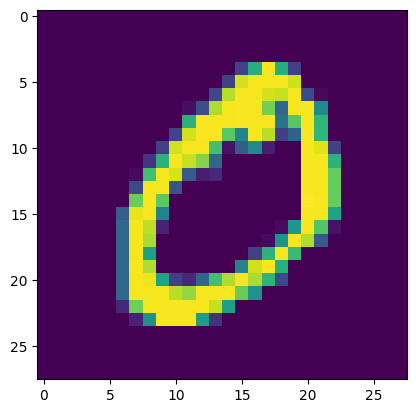

In [10]:
plt.imshow(x_train[1])

In [11]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [12]:
# Here in above cell we can see that the tensor value rages from 0 to 255
# so we'll hafta to scale it between 0 and 1

In [13]:
tf.keras.utils.normalize(x_train, axis = 1) # Pending to know why axis = 1?
x_test = tf.keras.utils.normalize(x_test)

In [14]:
model = Sequential()

In [15]:
# We know our pixels are in the form of matrix i.e 28*28. So, to input it in different layers,
# we need to arrange this rows side by size i.e after the first row, 2nd will start and so on
# Hence, we need to flatten our pixels for this
model.add(Flatten(input_shape = (28,28)))
model.add(Dense(256, activation = "relu"))
model.add(Dense(128, activation = "relu"))
model.add(Dense(64, activation = "relu"))
model.add(Dense(10, activation = 'softmax'))  # ALways remember: For classification,
                                              # containing multiple classes always use 'softmax' acti'on fun'on

In [16]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 256)               200960    
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dense_2 (Dense)             (None, 64)                8256      
                                                                 
 dense_3 (Dense)             (None, 10)                650       
                                                                 
Total params: 242762 (948.29 KB)
Trainable params: 242762 (948.29 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [17]:
model.compile(loss = "sparse_categorical_crossentropy", optimizer = 'Adam', metrics = "accuracy")
# In "sparse_categorical_croosentropy", we don't hafta do One-hot encoding
# whereas in 'categorical_cross_entropy' we'll hafta

In [18]:
history = model.fit(x_train, y_train, epochs = 25, validation_split = 0.2)

Epoch 1/25
1500/1500 [==============================] - 15s 9ms/step - loss: 1.1488 - accuracy: 0.8781 - val_loss: 0.3119 - val_accuracy: 0.9256
Epoch 2/25
1500/1500 [==============================] - 12s 8ms/step - loss: 0.2296 - accuracy: 0.9407 - val_loss: 0.2478 - val_accuracy: 0.9369
Epoch 3/25
1500/1500 [==============================] - 14s 9ms/step - loss: 0.1698 - accuracy: 0.9525 - val_loss: 0.1946 - val_accuracy: 0.9480
Epoch 4/25
1500/1500 [==============================] - 13s 9ms/step - loss: 0.1448 - accuracy: 0.9597 - val_loss: 0.1630 - val_accuracy: 0.9564
Epoch 5/25
1500/1500 [==============================] - 18s 12ms/step - loss: 0.1197 - accuracy: 0.9657 - val_loss: 0.1821 - val_accuracy: 0.9536
Epoch 6/25
1500/1500 [==============================] - 13s 9ms/step - loss: 0.1095 - accuracy: 0.9684 - val_loss: 0.1679 - val_accuracy: 0.9565
Epoch 7/25
1500/1500 [==============================] - 13s 9ms/step - loss: 0.0877 - accuracy: 0.9747 - val_loss: 0.1418 - val_a

In [19]:
probability = model.predict(x_test)
# As we've given 10 nodes in our output layer, this will give probability for each number i.e 1 to 9

313/313 [==============================] - 2s 4ms/step


In [27]:
probability[1]

array([0.10456815, 0.06761397, 0.10728174, 0.09693149, 0.07581057,
       0.0641748 , 0.06315076, 0.08328891, 0.23722325, 0.09995639],
      dtype=float32)

In [21]:
prediction = probability.argmax(axis = 1)

In [28]:
prediction[1]

8

In [22]:
# Now we'll find accuracy
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(prediction, y_test)

In [23]:
accuracy

0.0975

In [24]:
import matplotlib.pyplot as plt

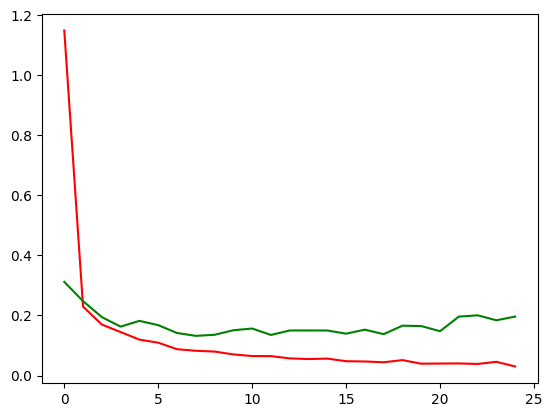

In [25]:
plt.plot(history.history['loss'], color = 'red')
plt.plot(history.history['val_loss'], color = 'green')